# Segmentation d'anomalies routières : U-Net + encodeur ResNet34 from scratch (poids aléatoires)

**Rôle de ce notebook :** entraîner et évaluer le **modèle principal** du projet (segmentation sémantique binaire : fond / anomalie), en réutilisant **exactement le même découpage train / val / test** que le notebook d'exploration (`split.csv`).

| Élément | Choix |
|---|---|
| Tâche | Segmentation binaire pixel par pixel (0 = route normale, 1 = anomalie) |
| Architecture | **U-Net** (encodeur-décodeur avec connexions de saut) |
| Encodeur | **ResNet34 initialisé aléatoirement** (from scratch, sans transfert d'apprentissage) |
| Perte | **BCE + Dice** (le fond représente 90 % des pixels) |
| Optimiseur | AdamW, learning rate plus faible pour l'encodeur pré-entraîné que pour le décodeur, planning cosinus |
| Évaluation | IoU, Dice, précision, rappel, F1 (globales et par image), analyse par groupe et par taille de région |
| Références de comparaison | Baseline « tout fond » et baseline « a priori de position » (carte de chaleur du train) |

**Variante from scratch :** mettre `ENCODER_WEIGHTS = None` dans la configuration (même architecture, poids aléatoires) : les résultats vont dans un autre dossier (`results/<prenom>/unet_resnet34_scratch`), ce qui permet une comparaison propre « pré-entraîné vs from scratch ».

**Pour l'exécuter :** ouvrir ce notebook depuis le dépôt (dossier `notebooks/<prenom>/`), choisir le kernel *RoadAnomaly venv*, puis *Run All*. Le dataset est retrouvé automatiquement. Mettre `QUICK_TEST = True` dans la cellule de configuration pour un test rapide (petite résolution, peu d'epochs).

> **Variante from scratch.** Identique à `01_unet_pretrained.ipynb` : seule l'initialisation de l'encodeur change (poids aléatoires au lieu d'ImageNet). Elle sert à mesurer l'apport du transfert d'apprentissage.

## 0. Environnement et configuration

In [3]:
import os, re, json, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp
from scipy import ndimage
from sklearn.model_selection import train_test_split
from IPython.display import display

# OpenCV ne doit pas lancer ses propres threads (évite les conflits avec PyTorch)
cv2.setNumThreads(0)

print("PyTorch :", torch.__version__, "| smp :", smp.__version__)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Périphérique :", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "pas de GPU (l'entraînement sera lent)")

PyTorch : 2.15.0+cpu | smp : 0.6.0
Périphérique : cpu | pas de GPU (l'entraînement sera lent)


In [4]:
# ============================================================
# CONFIGURATION (tout ce qu'on peut vouloir modifier est ici)
# ============================================================
STUDENT = "ahmed"         # dossier perso : results/<STUDENT>/ et models/<STUDENT>/
QUICK_TEST = False       # True = test rapide de la chaîne complète (petite résolution, peu d'epochs)

SEED = 42
ENCODER = "resnet34"
ENCODER_WEIGHTS = None      # "imagenet" = pré-entraîné (transfert) | None = FROM SCRATCH (poids aléatoires)
IMG_W, IMG_H = 512, 288           # multiples de 32 (exigence du U-Net), ratio 16:9 conservé
BATCH_SIZE = 4
EPOCHS = 60
PATIENCE = 15                     # arrêt anticipé si le Dice de validation ne progresse plus
LR_ENCODER = 1e-4                 # encodeur déjà entraîné : on le modifie doucement
LR_DECODER = 1e-3                 # décodeur initialisé au hasard : on peut aller plus vite
WEIGHT_DECAY = 1e-4
OVERFIT_STEPS = 60                # test de sanité (section 3)

if QUICK_TEST:
    IMG_W, IMG_H = 288, 160
    EPOCHS, PATIENCE, OVERFIT_STEPS = 12, 12, 25

# --- Chemins : le notebook fonctionne où qu'il soit dans le dépôt ---
def find_data_root():
    """Remonte l'arborescence jusqu'au dossier du dataset (frames/ + frame_list.json)."""
    here = os.path.abspath(os.getcwd())
    for _ in range(6):
        for cand in (here, os.path.join(here, "RoadAnomaly")):
            if os.path.exists(os.path.join(cand, "frames")) and os.path.exists(os.path.join(cand, "frame_list.json")):
                return cand
        here = os.path.dirname(here)
    raise FileNotFoundError(f"Dataset introuvable depuis {os.getcwd()} : ouvrir le notebook depuis le dépôt du projet.")

ROOT = find_data_root()                    # dossier du dataset : frames/, frame_list.json, split.csv
FRAMES = os.path.join(ROOT, "frames")
REPO_ROOT = os.path.dirname(ROOT)          # racine du dépôt
RUN_NAME = "unet_resnet34_" + ("pretrained" if ENCODER_WEIGHTS else "scratch")
SUFFIX = "_quick" if QUICK_TEST else ""
OUT_DIR = os.path.join(ROOT, "outputs_" + RUN_NAME + SUFFIX)   # tout au même endroit
MODELS_DIR = OUT_DIR
os.makedirs(OUT_DIR, exist_ok=True)                            # crée le dossier de sortie
CKPT_PATH = os.path.join(OUT_DIR, RUN_NAME + SUFFIX + "_best.pt")
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

print("Dossier de travail :", os.getcwd())
print("Dataset            :", ROOT)
print("Résolution réseau  :", (IMG_W, IMG_H), "| epochs :", EPOCHS, "| batch :", BATCH_SIZE)
print("Variante           :", RUN_NAME)
print("Résultats          :", OUT_DIR)
print("Poids              :", CKPT_PATH)


Dossier de travail : c:\Projects\deep_learning\RoadAnomaly\RoadAnomaly
Dataset            : c:\Projects\deep_learning\RoadAnomaly\RoadAnomaly
Résolution réseau  : (512, 288) | epochs : 60 | batch : 4
Variante           : unet_resnet34_scratch
Résultats          : c:\Projects\deep_learning\RoadAnomaly\RoadAnomaly\outputs_unet_resnet34_scratch
Poids              : c:\Projects\deep_learning\RoadAnomaly\RoadAnomaly\outputs_unet_resnet34_scratch\unet_resnet34_scratch_best.pt


## 1. Données : chargement et découpage train / val / test

Le découpage est celui du notebook d'exploration (stratifié sur **groupe + taille d'anomalie**, graine 42). Si `split.csv` existe on le lit ; sinon on le **recalcule à l'identique**. Dans les deux cas on vérifie qu'ils coïncident, ce qui garantit que **tous les modèles de l'équipe sont comparés sur les mêmes images**.

In [5]:
def get_paths(name):
    """Chemins de l'image et du masque à partir d'un nom de frame (avec ou sans .webp)."""
    base = os.path.splitext(name)[0]
    return base, os.path.join(FRAMES, base + ".webp"), os.path.join(FRAMES, base + ".labels", "labels_semantic.png")

def get_category(name):
    m = re.match(r"^([a-zA-Z_]+?)\d", name)
    return m.group(1) if m else "autre"

def build_split_df():
    """Recalcule le découpage exactement comme dans le notebook d'exploration."""
    with open(os.path.join(ROOT, "frame_list.json")) as f:
        frame_list = json.load(f)
    rows = []
    for name in frame_list:
        base, _, mask_p = get_paths(name)
        mask = np.array(Image.open(mask_p))
        rows.append({"name": base, "prop_anomalie": float((mask == 2).mean())})
    d = pd.DataFrame(rows)
    d["categorie"] = d["name"].apply(get_category)
    grandes = ["animals", "obstacles", "cones"]
    d["groupe"] = d["categorie"].apply(lambda c: c if c in grandes else "autres")
    seuil = d["prop_anomalie"].median()
    d["taille"] = np.where(d["prop_anomalie"] < seuil, "petite", "grande")
    d["strat"] = d["groupe"] + "_" + d["taille"]
    trainval, test = train_test_split(d, test_size=0.20, stratify=d["strat"], random_state=SEED)
    train, val = train_test_split(trainval, test_size=0.25, stratify=trainval["strat"], random_state=SEED)
    d["split"] = "train"
    d.loc[val.index, "split"] = "val"
    d.loc[test.index, "split"] = "test"
    return d

SPLIT_CSV = os.path.join(ROOT, "split.csv")
df_new = build_split_df()
if os.path.exists(SPLIT_CSV):
    df = pd.read_csv(SPLIT_CSV)
    same = dict(zip(df["name"], df["split"])) == dict(zip(df_new["name"], df_new["split"]))
    print("split.csv lu. Identique au découpage recalculé :", same)
else:
    df = df_new
    df[["name", "categorie", "groupe", "taille", "prop_anomalie", "split"]].to_csv(SPLIT_CSV, index=False)
    print("split.csv absent : découpage recalculé et sauvegardé.")

train_names = df[df["split"] == "train"]["name"].tolist()
val_names   = df[df["split"] == "val"]["name"].tolist()
test_names  = df[df["split"] == "test"]["name"].tolist()
all_names = train_names + val_names + test_names

# Pas de fuite de données : aucune image dans deux ensembles à la fois
assert not (set(train_names) & set(val_names)) and not (set(train_names) & set(test_names)) and not (set(val_names) & set(test_names))
assert len(set(all_names)) == len(df) == 60
print(f"train = {len(train_names)} | val = {len(val_names)} | test = {len(test_names)}")
print(pd.crosstab(df["split"], df["groupe"]))

split.csv lu. Identique au découpage recalculé : True
train = 36 | val = 12 | test = 12
groupe  animals  autres  cones  obstacles
split                                    
test          6       1      2          3
train        19       3      5          9
val           6       2      1          3


In [6]:
# Chargement en mémoire des 60 paires (image RGB, masque binaire 0/1) : ~220 Mo, entraînement bien plus rapide
def load_raw(name):
    _, img_p, mask_p = get_paths(name)
    img = np.array(Image.open(img_p).convert("RGB"))
    mask = (np.array(Image.open(mask_p)) == 2).astype(np.uint8)   # 2 (anomalie) -> 1, 0 (fond) -> 0
    assert img.shape[:2] == mask.shape, f"Image et masque de tailles différentes : {name}"
    return img, mask

CACHE = {n: load_raw(n) for n in all_names}
H_FULL, W_FULL = next(iter(CACHE.values()))[1].shape
print("Paires chargées :", len(CACHE), "| résolution d'origine :", (W_FULL, H_FULL))

Paires chargées : 60 | résolution d'origine : (1280, 720)


### 1.1 Dataset PyTorch et augmentations

- **Redimensionnement** : image en interpolation `INTER_AREA` (bon pour réduire), masque en `INTER_NEAREST` (**on n'interpole jamais des étiquettes**).
- **Normalisation ImageNet** : indispensable avec un encodeur pré-entraîné (le notebook d'exploration a montré que les statistiques du dataset en sont proches).
- **Augmentations (train uniquement)** : zoom/recadrage aléatoire (qui garde au moins un pixel d'anomalie), symétrie **horizontale**, luminosité/contraste. **Pas de symétrie verticale** : le ciel est toujours en haut, un U-Net apprend aussi ce contexte.
- Val et test ne sont **jamais** augmentés.

In [7]:
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def to_tensor(img_uint8):
    """Image uint8 (H, W, 3) -> tenseur float normalisé ImageNet (3, H, W)."""
    x = (img_uint8.astype(np.float32) / 255.0 - MEAN) / STD
    return torch.from_numpy(x.transpose(2, 0, 1).copy())

def resize_pair(img, mask, w=None, h=None):
    w, h = w or IMG_W, h or IMG_H
    img = cv2.resize(img, (w, h), interpolation=cv2.INTER_AREA)
    mask = cv2.resize(mask, (w, h), interpolation=cv2.INTER_NEAREST)
    return img, mask

class RoadAnomalyDataset(Dataset):
    def __init__(self, names, cache, train=False):
        self.names, self.cache, self.train = names, cache, train

    def __len__(self):
        return len(self.names)

    def augment(self, img, mask):
        H, W = mask.shape
        # 1) Zoom : recadrage aléatoire (50 à 100 % de l'image, ratio conservé) contenant de l'anomalie
        if random.random() < 0.7:
            for _ in range(5):
                s = random.uniform(0.5, 1.0)
                ch, cw = int(H * s), int(W * s)
                y0, x0 = random.randint(0, H - ch), random.randint(0, W - cw)
                m_crop = mask[y0:y0 + ch, x0:x0 + cw]
                if m_crop.sum() > 0:
                    img, mask = img[y0:y0 + ch, x0:x0 + cw], m_crop
                    break
        # 2) Symétrie horizontale
        if random.random() < 0.5:
            img, mask = img[:, ::-1], mask[:, ::-1]
        # 3) Contraste et luminosité
        a, b = random.uniform(0.8, 1.2), random.uniform(-20, 20)
        img = np.clip(img.astype(np.float32) * a + b, 0, 255).astype(np.uint8)
        return np.ascontiguousarray(img), np.ascontiguousarray(mask)

    def __getitem__(self, i):
        img, mask = self.cache[self.names[i]]
        if self.train:
            img, mask = self.augment(img, mask)
        img, mask = resize_pair(img, mask)
        return to_tensor(img), torch.from_numpy(mask.astype(np.float32))[None]   # (3,H,W), (1,H,W)

g = torch.Generator().manual_seed(SEED)
train_ds = RoadAnomalyDataset(train_names, CACHE, train=True)
val_ds   = RoadAnomalyDataset(val_names,   CACHE, train=False)
# num_workers=0 : évite les problèmes de multiprocessing sous Windows / notebooks
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, num_workers=0, generator=g)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print("Batches par epoch :", len(train_loader), "| batches de validation :", len(val_loader))

Batches par epoch : 9 | batches de validation : 3


## 2. Modèle, perte et métriques

**Pourquoi un U-Net ?** La tâche demande une décision **par pixel** avec des objets de tailles très différentes. L'encodeur extrait des caractéristiques de plus en plus abstraites en réduisant la résolution ; le décodeur remonte la résolution, et les **connexions de saut** réinjectent les détails fins de l'encodeur (contours, petits objets). C'est l'architecture de référence en segmentation avec peu de données.

**Pourquoi un encodeur ResNet34 pré-entraîné ?** Avec 36 images d'entraînement, apprendre des filtres visuels depuis zéro est impossible. L'encodeur ImageNet fournit déjà des filtres génériques (contours, textures, formes d'objets).

**Pourquoi BCE + Dice ?** Le fond représente 90 % des pixels : une BCE seule peut obtenir un bon score en prédisant presque tout en fond. Le Dice mesure directement le recouvrement avec l'anomalie, la BCE donne des gradients stables.

In [8]:
PRETRAINED_OK = ENCODER_WEIGHTS is not None   # passe à False si les poids ImageNet sont introuvables

def build_model():
    """U-Net + ResNet34. Si les poids ImageNet ne sont pas téléchargeables (hors-ligne), on prévient clairement."""
    global PRETRAINED_OK
    try:
        model = smp.Unet(ENCODER, encoder_weights=ENCODER_WEIGHTS, in_channels=3, classes=1)
    except Exception as e:
        PRETRAINED_OK = False
        print("!" * 70)
        print("ATTENTION : poids ImageNet indisponibles (connexion ?) -> encodeur initialisé AU HASARD.")
        print("Les résultats ne seront PAS représentatifs du transfert d'apprentissage.")
        print("Erreur :", type(e).__name__)
        print("!" * 70)
        model = smp.Unet(ENCODER, encoder_weights=None, in_channels=3, classes=1)
    return model.to(DEVICE)

class BCEDiceLoss(nn.Module):
    def __init__(self, w_bce=0.5, w_dice=0.5):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.dice = smp.losses.DiceLoss(mode="binary", from_logits=True)
        self.w_bce, self.w_dice = w_bce, w_dice
    def forward(self, logits, target):
        return self.w_bce * self.bce(logits, target) + self.w_dice * self.dice(logits, target)

def metrics_from_counts(tp, fp, fn, eps=1e-9):
    """Métriques pixel à partir des comptes TP/FP/FN (le fond bien classé, TN, ne compte pas dans ces métriques)."""
    precision = tp / (tp + fp + eps)
    recall    = tp / (tp + fn + eps)
    f1        = 2 * precision * recall / (precision + recall + eps)
    iou       = tp / (tp + fp + fn + eps)
    dice      = 2 * tp / (2 * tp + fp + fn + eps)
    return {"iou": iou, "dice": dice, "precision": precision, "recall": recall, "f1": f1}

model = build_model()
n_params = sum(p.numel() for p in model.parameters())
n_enc = sum(p.numel() for p in model.encoder.parameters())
print(f"Paramètres totaux : {n_params/1e6:.1f} M  (encodeur : {n_enc/1e6:.1f} M, décodeur + tête : {(n_params-n_enc)/1e6:.1f} M)")
x_test = torch.randn(2, 3, IMG_H, IMG_W, device=DEVICE)
with torch.no_grad():
    print("Entrée :", tuple(x_test.shape), "-> sortie :", tuple(model.eval()(x_test).shape), "(logits, 1 canal)")

Paramètres totaux : 24.4 M  (encodeur : 21.3 M, décodeur + tête : 3.2 M)
Entrée : (2, 3, 288, 512) -> sortie : (2, 1, 288, 512) (logits, 1 canal)


> **Remarque pour l'oral : Dice et F1 sont identiques.** Pour une segmentation binaire, `Dice = 2TP / (2TP + FP + FN)` est exactement le F1-score calculé sur les pixels. Le sujet demande les deux, on les calcule donc séparément (par `precision`/`recall`) pour le vérifier, mais ils donnent la même valeur. L'IoU est liée au Dice par `Dice = 2·IoU / (1 + IoU)`.

## 3. Tests de sanité (avant le vrai entraînement)

Trois vérifications pour être sûr que la chaîne est correcte **avant** d'attendre un long entraînement :

1. **Alignement image ↔ masque après augmentation** (contrôle visuel).
2. **Format des données** (formes, types, valeurs des masques).
3. **Test de sur-apprentissage** : un bon pipeline doit savoir apprendre *par cœur* 4 images. Si la perte ne baisse pas, il y a un bug (étiquettes, perte, learning rate...), pas un problème de généralisation.

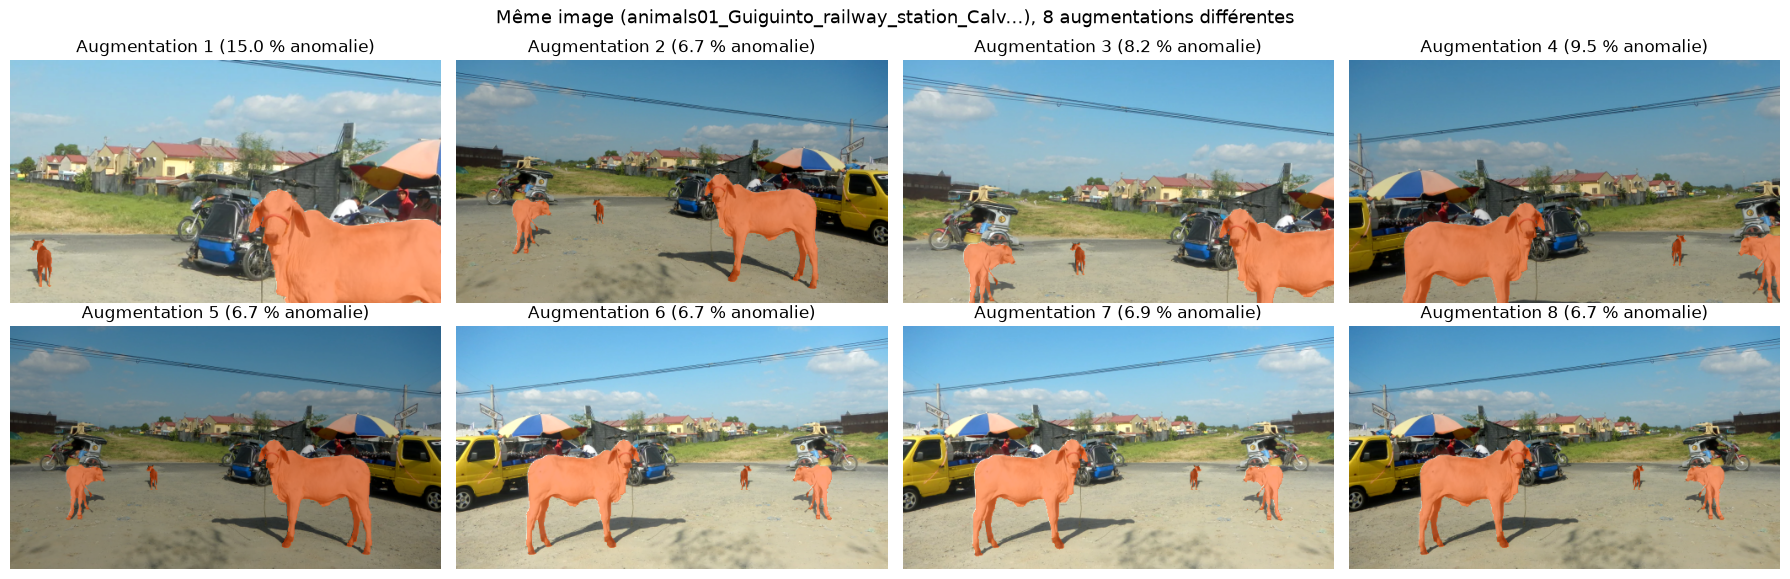

Batch image  : (4, 3, 288, 512) torch.float32 | moyenne -0.27, écart-type 1.08 (attendu ~0 et ~1)
Batch masque : (4, 1, 288, 512) torch.float32 | valeurs : [0.0, 1.0]
Formats corrects.


In [9]:
# 1) Alignement après augmentation : l'overlay orange doit toujours recouvrir l'objet
def make_overlay(img, mask, color=(255, 69, 0), alpha=0.5):
    out = img.astype(np.float32).copy()
    out[mask == 1] = (1 - alpha) * out[mask == 1] + alpha * np.array(color, dtype=np.float32)
    return out.astype(np.uint8)

def denorm(x):
    """Tenseur normalisé (3,H,W) -> image uint8 (H,W,3) pour l'affichage."""
    img = x.numpy().transpose(1, 2, 0) * STD + MEAN
    return (np.clip(img, 0, 1) * 255).astype(np.uint8)

set_seed()
aug_ds = RoadAnomalyDataset(train_names[:1], CACHE, train=True)
fig, axes = plt.subplots(2, 4, figsize=(18, 6))
for ax, k in zip(axes.ravel(), range(8)):
    x, y = aug_ds[0]
    ax.imshow(make_overlay(denorm(x), y[0].numpy().astype(np.uint8)))
    ax.set_title(f"Augmentation {k + 1} ({100 * y.mean():.1f} % anomalie)"); ax.axis("off")
fig.suptitle(f"Même image ({train_names[0][:40]}...), 8 augmentations différentes", fontsize=13)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "augmentations.png"), dpi=110, bbox_inches="tight"); plt.show()

# 2) Format des données
xb, yb = next(iter(train_loader))
print("Batch image  :", tuple(xb.shape), xb.dtype, f"| moyenne {xb.mean():.2f}, écart-type {xb.std():.2f} (attendu ~0 et ~1)")
print("Batch masque :", tuple(yb.shape), yb.dtype, "| valeurs :", torch.unique(yb).tolist())
assert xb.shape == (BATCH_SIZE, 3, IMG_H, IMG_W) and yb.shape == (BATCH_SIZE, 1, IMG_H, IMG_W)
assert set(torch.unique(yb).tolist()) <= {0.0, 1.0}
print("Formats corrects.")

Perte : 0.773 -> 0.067 après 60 pas | Dice sur ces 4 images : 0.971


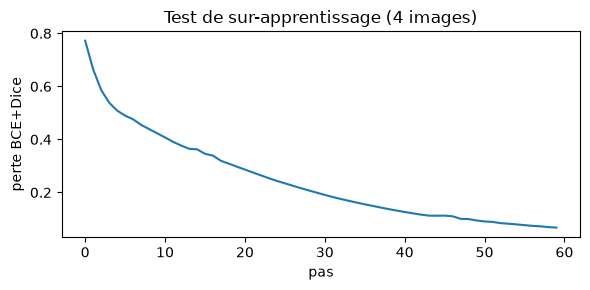

Test réussi : le modèle sait apprendre.


In [10]:
# 3) Test de sur-apprentissage : 4 images, sans augmentation, on doit voir la perte chuter
def overfit_test(n_images=4, steps=OVERFIT_STEPS):
    set_seed()
    ds = RoadAnomalyDataset(train_names[:n_images], CACHE, train=False)
    x, y = next(iter(DataLoader(ds, batch_size=n_images)))
    x, y = x.to(DEVICE), y.to(DEVICE)
    m = build_model()
    crit, opt = BCEDiceLoss(), torch.optim.Adam(m.parameters(), lr=1e-3)
    losses = []
    m.train()
    for step in range(steps):
        opt.zero_grad(); loss = crit(m(x), y); loss.backward(); opt.step()
        losses.append(loss.item())
    m.eval()
    with torch.no_grad():
        pred = torch.sigmoid(m(x)) >= 0.5
    gt = y > 0.5
    tp = (pred & gt).sum().item(); fp = (pred & ~gt).sum().item(); fn = (~pred & gt).sum().item()
    return losses, metrics_from_counts(tp, fp, fn)

losses, m_over = overfit_test()
print(f"Perte : {losses[0]:.3f} -> {losses[-1]:.3f} après {len(losses)} pas | Dice sur ces 4 images : {m_over['dice']:.3f}")
plt.figure(figsize=(6, 3)); plt.plot(losses); plt.xlabel("pas"); plt.ylabel("perte BCE+Dice"); plt.title("Test de sur-apprentissage (4 images)")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "overfit_test.png"), dpi=110); plt.show()
assert losses[-1] < 0.7 * losses[0], "La perte ne diminue pas : bug dans la chaîne (données, perte ou optimiseur)."
print("Test réussi : le modèle sait apprendre.")

## 4. Entraînement

- **Taux d'apprentissage différenciés** : 1e-4 pour l'encodeur pré-entraîné (on ajuste sans détruire ce qu'il sait), 1e-3 pour le décodeur (initialisé au hasard).
- **Planning cosinus** : le taux décroît en douceur jusqu'à la fin.
- **Sélection du meilleur modèle** sur le **Dice de validation** (seuil 0,5, résolution du réseau) et **arrêt anticipé** : on garde les poids de la meilleure epoch, pas ceux de la dernière.
- Précision mixte (fp16) automatiquement activée si GPU.

In [11]:
@torch.no_grad()
def validate(model, loader, criterion):
    """Perte et métriques globales sur un loader (résolution du réseau, seuil 0.5)."""
    model.eval()
    tot, n, tp, fp, fn = 0.0, 0, 0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)
        tot += criterion(logits, y).item() * x.size(0); n += x.size(0)
        pred, gt = torch.sigmoid(logits) >= 0.5, y > 0.5
        tp += (pred & gt).sum().item(); fp += (pred & ~gt).sum().item(); fn += (~pred & gt).sum().item()
    return tot / n, metrics_from_counts(tp, fp, fn)

def fit(model, train_loader, val_loader, epochs, patience, ckpt_path):
    criterion = BCEDiceLoss()
    enc_ids = {id(p) for p in model.encoder.parameters()}
    dec_params = [p for p in model.parameters() if id(p) not in enc_ids]
    optimizer = torch.optim.AdamW(
        [{"params": model.encoder.parameters(), "lr": LR_ENCODER}, {"params": dec_params, "lr": LR_DECODER}],
        weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)
    use_amp = DEVICE == "cuda"
    scaler = torch.amp.GradScaler(DEVICE, enabled=use_amp)

    hist = {"train_loss": [], "val_loss": [], "val_dice": [], "val_iou": [], "lr": []}
    best, best_epoch, best_state, t0 = -1.0, 0, None, time.time()
    for epoch in range(1, epochs + 1):
        model.train(); run, n = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=use_amp):
                logits = model(x)
            loss = criterion(logits.float(), y)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
            run += loss.item() * x.size(0); n += x.size(0)
        scheduler.step()
        val_loss, vm = validate(model, val_loader, criterion)
        hist["train_loss"].append(run / n); hist["val_loss"].append(val_loss)
        hist["val_dice"].append(vm["dice"]); hist["val_iou"].append(vm["iou"]); hist["lr"].append(optimizer.param_groups[0]["lr"])

        improved = vm["dice"] > best
        if improved:
            best, best_epoch = vm["dice"], epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            torch.save({"state_dict": best_state, "epoch": epoch, "val_dice": best, "img_size": (IMG_W, IMG_H), "encoder": ENCODER}, ckpt_path)
        print(f"Epoch {epoch:3d}/{epochs} | train {hist['train_loss'][-1]:.4f} | val {val_loss:.4f} | val Dice {vm['dice']:.4f} | val IoU {vm['iou']:.4f}" + ("  <- meilleur" if improved else ""))
        if epoch - best_epoch >= patience:
            print(f"Arrêt anticipé : pas d'amélioration depuis {patience} epochs."); break
    model.load_state_dict(best_state)       # on revient aux meilleurs poids
    print(f"\nTerminé en {(time.time() - t0) / 60:.1f} min | meilleure epoch : {best_epoch} (Dice validation = {best:.4f})")
    return hist, best_epoch

set_seed()
model = build_model()
history, best_epoch = fit(model, train_loader, val_loader, EPOCHS, PATIENCE, CKPT_PATH)

Epoch   1/60 | train 0.7560 | val 0.8755 | val Dice 0.2382 | val IoU 0.1352  <- meilleur
Epoch   2/60 | train 0.6325 | val 0.7029 | val Dice 0.2990 | val IoU 0.1758  <- meilleur
Epoch   3/60 | train 0.5799 | val 0.5379 | val Dice 0.5028 | val IoU 0.3358  <- meilleur
Epoch   4/60 | train 0.5366 | val 0.5386 | val Dice 0.4174 | val IoU 0.2637
Epoch   5/60 | train 0.5338 | val 0.5444 | val Dice 0.4320 | val IoU 0.2755
Epoch   6/60 | train 0.5396 | val 0.5011 | val Dice 0.4657 | val IoU 0.3035
Epoch   7/60 | train 0.4940 | val 0.4734 | val Dice 0.4727 | val IoU 0.3095
Epoch   8/60 | train 0.4960 | val 0.5854 | val Dice 0.3769 | val IoU 0.2322
Epoch   9/60 | train 0.4737 | val 0.5052 | val Dice 0.4678 | val IoU 0.3053
Epoch  10/60 | train 0.4989 | val 0.4968 | val Dice 0.4270 | val IoU 0.2715
Epoch  11/60 | train 0.5129 | val 0.4612 | val Dice 0.4976 | val IoU 0.3312
Epoch  12/60 | train 0.4844 | val 0.4195 | val Dice 0.5952 | val IoU 0.4237  <- meilleur
Epoch  13/60 | train 0.4861 | val 0.

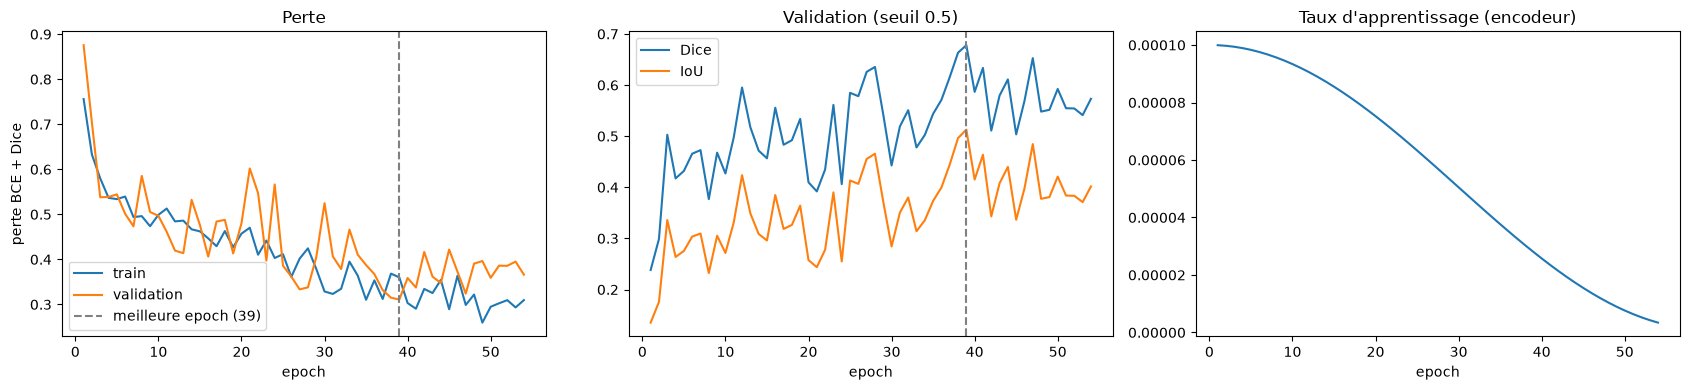

In [12]:
# Courbes d'apprentissage
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
ep = np.arange(1, len(history["train_loss"]) + 1)
axes[0].plot(ep, history["train_loss"], label="train"); axes[0].plot(ep, history["val_loss"], label="validation")
axes[0].axvline(best_epoch, color="gray", ls="--", label=f"meilleure epoch ({best_epoch})")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("perte BCE + Dice"); axes[0].set_title("Perte"); axes[0].legend()
axes[1].plot(ep, history["val_dice"], label="Dice"); axes[1].plot(ep, history["val_iou"], label="IoU")
axes[1].axvline(best_epoch, color="gray", ls="--"); axes[1].set_xlabel("epoch"); axes[1].set_title("Validation (seuil 0.5)"); axes[1].legend()
axes[2].plot(ep, history["lr"]); axes[2].set_xlabel("epoch"); axes[2].set_title("Taux d'apprentissage (encodeur)")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "courbes_apprentissage.png"), dpi=110, bbox_inches="tight"); plt.show()

## 5. Évaluation

On évalue **à la résolution d'origine (1280×720)** : la carte de probabilité du réseau est agrandie, puis comparée au masque d'origine. C'est plus exigeant que d'évaluer à basse résolution, car les très petits objets perdus au redimensionnement comptent comme des erreurs.

**Seuil de décision** : choisi sur la **validation** (jamais sur le test), puis appliqué tel quel au test.

Prédictions calculées en 10 s
Seuil retenu (meilleur Dice sur la validation) : 0.75


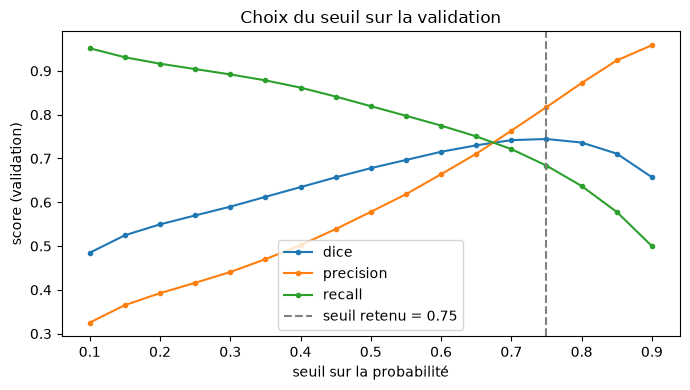

In [13]:
@torch.no_grad()
def predict_probs(model, names, tta=False, bs=4):
    """Probabilités d'anomalie à la résolution d'origine, dict {nom: tableau float32 (720, 1280)}."""
    model.eval(); out = {}
    for i in range(0, len(names), bs):
        batch = names[i:i + bs]
        x = torch.stack([to_tensor(cv2.resize(CACHE[n][0], (IMG_W, IMG_H), interpolation=cv2.INTER_AREA)) for n in batch]).to(DEVICE)
        logits = model(x)
        if tta:   # test-time augmentation : moyenne avec l'image retournée horizontalement
            logits = (logits + torch.flip(model(torch.flip(x, dims=[3])), dims=[3])) / 2
        probs = torch.sigmoid(F.interpolate(logits, size=(H_FULL, W_FULL), mode="bilinear", align_corners=False))
        for n, p in zip(batch, probs[:, 0].cpu().numpy()):
            out[n] = p.astype(np.float32)
    return out

def global_counts(names, probs, thr):
    tp = fp = fn = 0
    for n in names:
        gt, pred = CACHE[n][1].astype(bool), probs[n] >= thr
        tp += int((pred & gt).sum()); fp += int((pred & ~gt).sum()); fn += int((~pred & gt).sum())
    return tp, fp, fn

def sweep_threshold(names, probs, thresholds):
    rows = [{"thr": t, **metrics_from_counts(*global_counts(names, probs, t))} for t in thresholds]
    r = pd.DataFrame(rows)
    return r, float(r.loc[r["dice"].idxmax(), "thr"])

def evaluate(names, probs, thr):
    """Renvoie (métriques globales 'micro', tableau par image, moyennes par image 'macro')."""
    rows = []
    for n in names:
        gt, pred = CACHE[n][1].astype(bool), probs[n] >= thr
        tp, fp, fn = int((pred & gt).sum()), int((pred & ~gt).sum()), int((~pred & gt).sum())
        rows.append({"name": n, "tp": tp, "fp": fp, "fn": fn, **metrics_from_counts(tp, fp, fn)})
    per_img = pd.DataFrame(rows)
    glob = metrics_from_counts(per_img["tp"].sum(), per_img["fp"].sum(), per_img["fn"].sum())
    macro = per_img[["iou", "dice", "precision", "recall", "f1"]].mean().to_dict()
    return glob, per_img, macro

t0 = time.time()
probs_train = predict_probs(model, train_names)
probs_val   = predict_probs(model, val_names)
probs_test  = predict_probs(model, test_names)
print(f"Prédictions calculées en {time.time() - t0:.0f} s")

thresholds = np.round(np.arange(0.10, 0.91, 0.05), 2)
sweep_val, THR = sweep_threshold(val_names, probs_val, thresholds)
print(f"Seuil retenu (meilleur Dice sur la validation) : {THR:.2f}")

plt.figure(figsize=(7, 4))
for k in ["dice", "precision", "recall"]:
    plt.plot(sweep_val["thr"], sweep_val[k], marker="o", ms=3, label=k)
plt.axvline(THR, color="gray", ls="--", label=f"seuil retenu = {THR:.2f}")
plt.xlabel("seuil sur la probabilité"); plt.ylabel("score (validation)"); plt.title("Choix du seuil sur la validation"); plt.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "choix_seuil.png"), dpi=110); plt.show()

### 5.1 Résultats train / validation / test et comparaison aux références

- **Baseline « tout fond »** : prédit toujours « pas d'anomalie » (IoU = 0). Rappelle qu'avec 90 % de fond, la *précision globale* (accuracy) serait trompeuse : on ne l'utilise pas.
- **Baseline « a priori de position »** : sans regarder l'image, prédit « anomalie » là où elle est fréquente dans les masques d'entraînement (la zone centrale vue dans la carte de chaleur). Le modèle doit faire **nettement mieux** pour prouver qu'il a appris à *voir* les anomalies et pas seulement leur position.
- **Micro** = pixels de toutes les images regroupés (dominé par les grands objets). **Macro** = moyenne des scores par image (chaque image compte autant).

In [14]:
# Baseline a priori de position : carte de chaleur des masques d'entraînement, seuil choisi sur la validation
heat = np.mean([CACHE[n][1] for n in train_names], axis=0).astype(np.float32)
prior_val  = {n: heat for n in val_names}
prior_test = {n: heat for n in test_names}
_, THR_PRIOR = sweep_threshold(val_names, prior_val, np.round(np.linspace(0.02, 0.6, 30), 3))

# Tableau récapitulatif
g_train, _, mac_train = evaluate(train_names, probs_train, THR)
g_val,   _, mac_val   = evaluate(val_names,   probs_val,   THR)
g_test, per_img_test, mac_test = evaluate(test_names, probs_test, THR)
g_prior, _, mac_prior = evaluate(test_names, prior_test, THR_PRIOR)
g_zero = metrics_from_counts(0, 0, int(sum(CACHE[n][1].sum() for n in test_names)))

def row(label, g, mac=None):
    r = {"Modèle / ensemble": label, "IoU": g["iou"], "Dice = F1": g["dice"], "Précision": g["precision"], "Rappel": g["recall"]}
    r["IoU moy. par image"] = mac["iou"] if mac else np.nan
    return r

summary = pd.DataFrame([
    row("Baseline tout fond (test)", g_zero),
    row(f"Baseline a priori de position (test, seuil {THR_PRIOR:.2f})", g_prior, mac_prior),
    row("U-Net ResNet34 : train", g_train, mac_train),
    row("U-Net ResNet34 : validation", g_val, mac_val),
    row("U-Net ResNet34 : TEST", g_test, mac_test),
]).set_index("Modèle / ensemble").round(3)
print(f"Seuil du U-Net : {THR:.2f} | encodeur pré-entraîné ImageNet : {PRETRAINED_OK}\n")
display(summary)
print("\nTest, moyennes par image (macro) :", {k: round(v, 3) for k, v in mac_test.items()})

Seuil du U-Net : 0.75 | encodeur pré-entraîné ImageNet : False



,IoU,Dice = F1,Précision,Rappel,IoU moy. par image
Modèle / ensemble,,,,,
Baseline tout fond (test),0.000,0.000,0.000,0.000,NaN
"Baseline a priori de position (test, seuil 0.18)",0.186,0.314,0.205,0.673,0.183
U-Net ResNet34 : train,0.550,0.710,0.803,0.636,0.401
U-Net ResNet34 : validation,0.593,0.744,0.817,0.684,0.446
U-Net ResNet34 : TEST,0.339,0.507,0.580,0.450,0.286



Test, moyennes par image (macro) : {'iou': 0.286, 'dice': 0.414, 'precision': 0.601, 'recall': 0.417, 'f1': 0.414}


In [15]:
# Effet du test-time augmentation (moyenne avec l'image retournée) : à titre indicatif, sur la validation et le test
probs_val_tta, probs_test_tta = predict_probs(model, val_names, tta=True), predict_probs(model, test_names, tta=True)
g_val_tta, _, _  = evaluate(val_names,  probs_val_tta,  THR)
g_test_tta, _, _ = evaluate(test_names, probs_test_tta, THR)
print(f"Dice validation : {g_val['dice']:.3f} -> {g_val_tta['dice']:.3f} avec TTA")
print(f"Dice test       : {g_test['dice']:.3f} -> {g_test_tta['dice']:.3f} avec TTA")
print("(Le résultat officiel reste celui SANS TTA ci-dessus ; le TTA est une piste d'amélioration.)")

Dice validation : 0.744 -> 0.740 avec TTA
Dice test       : 0.507 -> 0.506 avec TTA
(Le résultat officiel reste celui SANS TTA ci-dessus ; le TTA est une piste d'amélioration.)


### 5.2 Analyse par groupe et par taille de région

Le notebook d'exploration a montré que la taille des anomalies dépend fortement du groupe et que **63 % des régions font moins de 500 pixels**. On regarde donc :

- les scores **par groupe** (animals / obstacles / cones / autres) ;
- le **rappel par région** : une région d'anomalie du masque est « détectée » si au moins 50 % de ses pixels sont prédits ; on sépare les petites (< 500 px) des grandes (≥ 500 px) ;
- les **fausses alarmes** : régions prédites qui ne touchent aucune vraie anomalie.

In [16]:
# Par groupe (sur le test)
grp = per_img_test.merge(df[["name", "groupe"]], on="name")
by_group = grp.groupby("groupe").agg(
    n_images=("name", "count"), TP=("tp", "sum"), FP=("fp", "sum"), FN=("fn", "sum")).reset_index()
for k in ["iou", "dice", "precision", "recall"]:
    by_group[k] = [metrics_from_counts(r.TP, r.FP, r.FN)[k] for r in by_group.itertuples()]
print("Test, par groupe (pixels regroupés par groupe) :")
print(by_group.drop(columns=["TP", "FP", "FN"]).round(3).to_string(index=False))

# Par région
def region_analysis(names, probs, thr, small_px=500):
    rows, fp_regions = [], 0
    for n in names:
        gt, pred = CACHE[n][1], probs[n] >= thr
        lab, k = ndimage.label(gt)
        for r in range(1, k + 1):
            reg = lab == r
            rows.append({"name": n, "taille_px": int(reg.sum()), "frac_predite": float(pred[reg].mean())})
        lab_p, kp = ndimage.label(pred)
        if kp:
            overlap = np.array(ndimage.sum(gt, lab_p, index=range(1, kp + 1)))
            fp_regions += int((overlap == 0).sum())
    d = pd.DataFrame(rows)
    d["detectee"] = d["frac_predite"] >= 0.5
    d["classe"] = np.where(d["taille_px"] < small_px, f"petite (< {small_px} px)", f"grande (>= {small_px} px)")
    return d, fp_regions

reg_df, fp_regions = region_analysis(test_names, probs_test, THR)
reg_sum = reg_df.groupby("classe").agg(regions=("detectee", "size"), detectees=("detectee", "sum"), rappel_regions=("detectee", "mean")).round(3)
reg_sum.loc["TOUTES"] = [len(reg_df), int(reg_df["detectee"].sum()), round(reg_df["detectee"].mean(), 3)]
print("\nTest, rappel par région :")
print(reg_sum.to_string())
print(f"\nFausses alarmes (régions prédites sans aucun recouvrement avec une vraie anomalie) : {fp_regions}")

Test, par groupe (pixels regroupés par groupe) :
   groupe  n_images   iou  dice  precision  recall
  animals         6 0.193 0.323      0.543   0.230
   autres         1 0.215 0.354      0.955   0.217
    cones         2 0.217 0.357      0.267   0.537
obstacles         3 0.543 0.704      0.616   0.821

Test, rappel par région :
                    regions  detectees  rappel_regions
classe                                                
grande (>= 500 px)       24         11           0.458
petite (< 500 px)        48          9           0.188
TOUTES                   72         20           0.278

Fausses alarmes (régions prédites sans aucun recouvrement avec une vraie anomalie) : 60


### 5.3 Visualisation des prédictions sur le test

Colonnes : image, vérité terrain (orange), **carte de probabilité** du modèle, et **carte d'erreurs** : <span style="color:green">vert = vrai positif</span>, <span style="color:red">rouge = faux positif (fausse alarme)</span>, <span style="color:#0078ff">bleu = faux négatif (anomalie manquée)</span>. Les images sont triées de la meilleure à la moins bonne IoU.

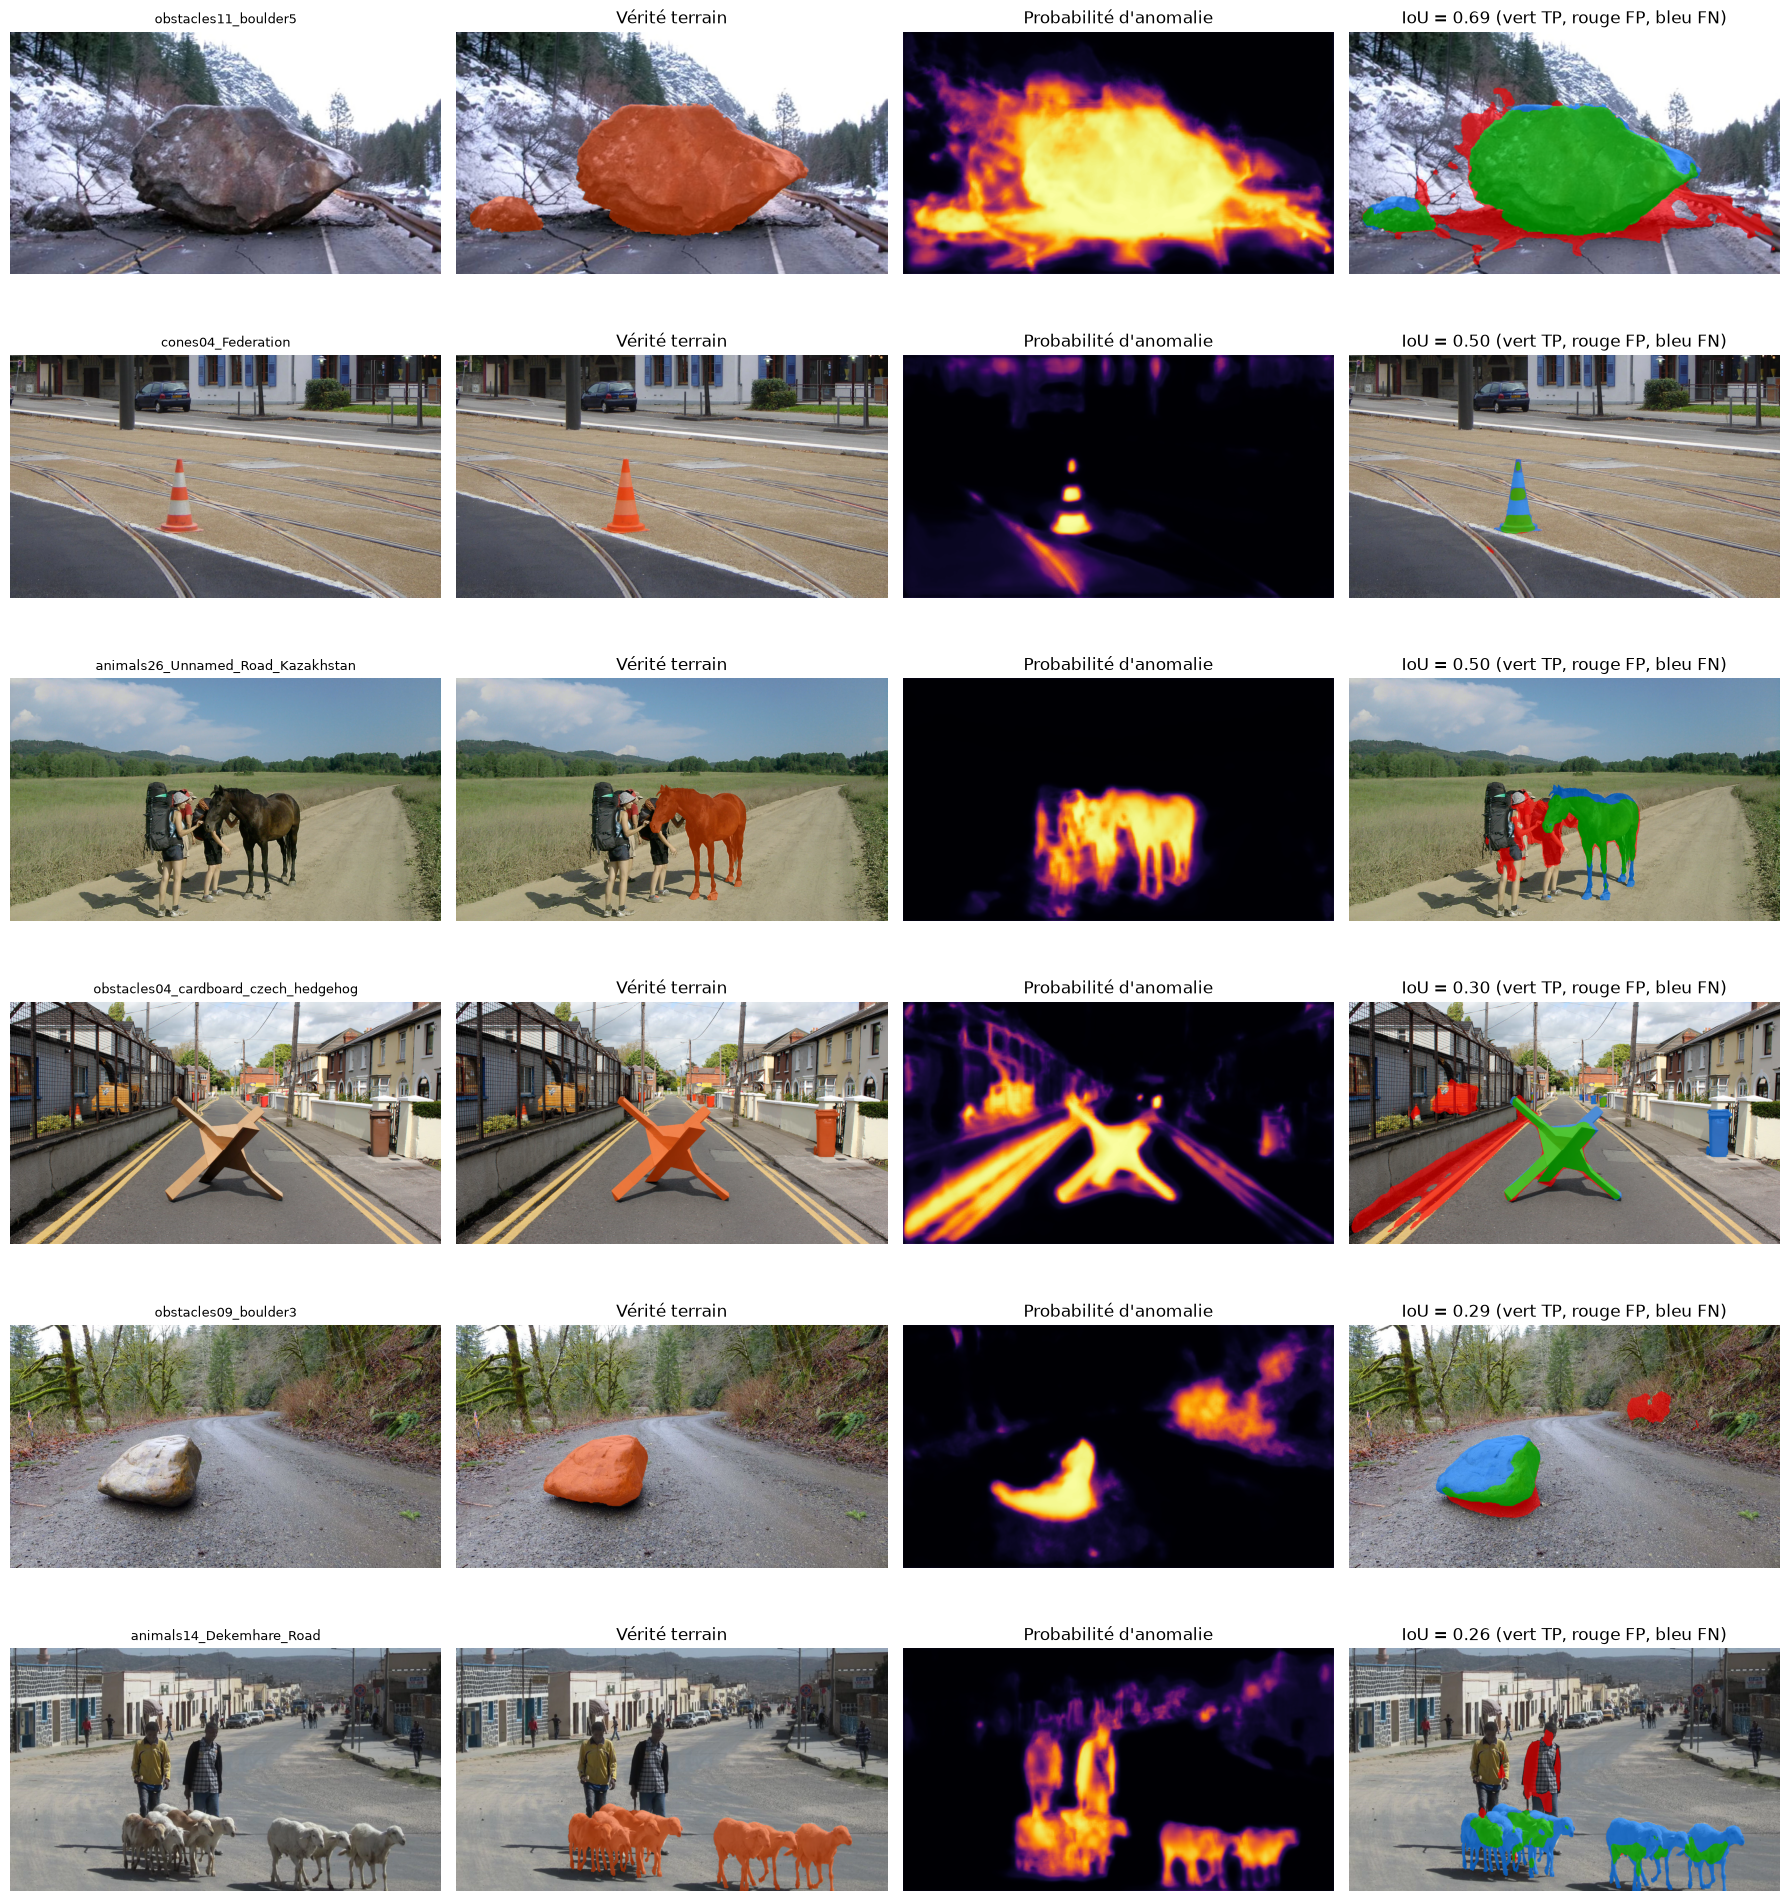

In [ ]:
def error_overlay(img, gt, pred, alpha=0.65):
    out = img.astype(np.float32).copy()
    for mask, color in [(gt & pred, (0, 200, 0)), (~gt & pred, (255, 0, 0)), (gt & ~pred, (0, 120, 255))]:
        out[mask] = (1 - alpha) * out[mask] + alpha * np.array(color, dtype=np.float32)
    return out.astype(np.uint8)

def show_predictions(names, probs, thr, per_img, fname, rows_per_fig=6):
    ious = per_img.set_index("name")["iou"]
    names = sorted(names, key=lambda n: -ious[n])
    for part, start in enumerate(range(0, len(names), rows_per_fig)):
        chunk = names[start:start + rows_per_fig]
        fig, axes = plt.subplots(len(chunk), 4, figsize=(18, 3.3 * len(chunk)), squeeze=False)
        for r, n in enumerate(chunk):
            img, gt = CACHE[n][0], CACHE[n][1].astype(bool)
            pred = probs[n] >= thr
            axes[r, 0].imshow(img); axes[r, 0].set_title(n[:38], fontsize=9)
            axes[r, 1].imshow(make_overlay(img, gt.astype(np.uint8))); axes[r, 1].set_title("Vérité terrain")
            axes[r, 2].imshow(probs[n], cmap="inferno", vmin=0, vmax=1); axes[r, 2].set_title("Probabilité d'anomalie")
            axes[r, 3].imshow(error_overlay(img, gt, pred))
            axes[r, 3].set_title(f"IoU = {ious[n]:.2f} (vert TP, rouge FP, bleu FN)")
            for ax in axes[r]: ax.axis("off")
        plt.tight_layout()
        plt.savefig(os.path.join(OUT_DIR, f"{fname}_{part + 1}.png"), dpi=100, bbox_inches="tight"); plt.show()

show_predictions(test_names, probs_test, THR, per_img_test, "predictions_test")

In [ ]:
# Détail par image (test), du meilleur au pire
detail = per_img_test.merge(df[["name", "groupe", "prop_anomalie"]], on="name")
detail["anomalie_%"] = (100 * detail["prop_anomalie"]).round(2)
print(detail.sort_values("iou", ascending=False)[["name", "groupe", "anomalie_%", "iou", "dice", "precision", "recall"]].round(3).to_string(index=False))

                                        name    groupe  anomalie_%   iou  dice  precision  recall
                        obstacles09_boulder3 obstacles        5.14 0.529 0.692      0.770   0.629
                        obstacles11_boulder5 obstacles       22.72 0.467 0.637      0.693   0.589
        vehicle02_Broadmoor_Cones_Skidloader    autres        9.97 0.448 0.619      0.900   0.472
        obstacles04_cardboard_czech_hedgehog obstacles        4.75 0.306 0.469      0.321   0.870
                                   animals30   animals        6.64 0.296 0.457      0.445   0.470
                  animals19_Porte_de_Roubaix   animals        9.43 0.276 0.432      0.461   0.407
animals12_Collared_Peccary_crossing_the_road   animals       13.03 0.264 0.418      0.282   0.806
                          cones04_Federation     cones        1.31 0.262 0.416      0.262   1.000
           animals26_Unnamed_Road_Kazakhstan   animals        4.91 0.258 0.410      0.400   0.420
                    

## 6. Sauvegarde des résultats

In [ ]:
results = {
    "config": {"run_name": RUN_NAME, "encoder": ENCODER, "pretrained_imagenet": bool(PRETRAINED_OK), "img_size": [IMG_W, IMG_H], "batch_size": BATCH_SIZE,
               "epochs_max": EPOCHS, "best_epoch": int(best_epoch), "lr_encoder": LR_ENCODER, "lr_decoder": LR_DECODER, "seed": SEED, "quick_test": QUICK_TEST},
    "threshold": THR,
    "test_global": {k: float(v) for k, v in g_test.items()},
    "test_macro_per_image": {k: float(v) for k, v in mac_test.items()},
    "val_global": {k: float(v) for k, v in g_val.items()},
    "baseline_prior_test": {k: float(v) for k, v in g_prior.items()},
}
with open(os.path.join(OUT_DIR, "resultats_unet.json"), "w") as f:
    json.dump(results, f, indent=2)
detail.to_csv(os.path.join(OUT_DIR, "resultats_par_image_test.csv"), index=False)
summary.to_csv(os.path.join(OUT_DIR, "tableau_recapitulatif.csv"))
print("Fichiers sauvegardés dans", OUT_DIR, ":", sorted(os.listdir(OUT_DIR)))

Fichiers sauvegardés dans c:\Projects\deep_learning\RoadAnomaly\RoadAnomaly\outputs_unet_resnet34_scratch_quick : ['augmentations.png', 'choix_seuil.png', 'courbes_apprentissage.png', 'overfit_test.png', 'predictions_test_1.png', 'predictions_test_2.png', 'resultats_par_image_test.csv', 'resultats_unet.json', 'tableau_recapitulatif.csv', 'unet_resnet34_scratch_quick_best.pt']


## 7. Discussion et analyse critique

**Ce que le modèle doit apporter (à confirmer avec vos chiffres).** Le U-Net avec encodeur pré-entraîné doit dépasser nettement l'a priori de position du tableau 5.1 : c'est la preuve qu'il a appris à *voir* les anomalies et pas seulement à deviner où elles se trouvent. Le transfert d'apprentissage en est la raison : les filtres ImageNet sont réutilisés, seul le décodeur doit être appris presque entièrement avec 36 images.

**Limites à discuter (à relier à vos chiffres) :**

1. **Très peu de données** : 12 images de test, donc des métriques **bruitées** (une seule image peut déplacer l'IoU globale de plusieurs points). Les résultats sont à lire comme des ordres de grandeur, pas comme des classements fins entre modèles proches.
2. **Petits objets** : cônes et pneus lointains font quelques dizaines de pixels. Le redimensionnement (1280×720 → réseau) et les pas de sous-échantillonnage du ResNet les fragilisent. Le rappel par région sépare petites et grandes régions pour le montrer.
3. **Annotations approximatives** sur les formes complexes (pattes, foin) : une partie des « erreurs » de contour vient du masque lui-même. Regarder aussi les zones **rouges** (fausses alarmes) : certaines correspondent à des objets que le masque ne considère pas comme anomalie (piétons, bâtiments, végétation sombre).
4. **Approche supervisée, donc *fermée*** : le modèle apprend les types d'anomalies vus à l'entraînement (animaux, cônes, obstacles...). Il n'est **pas** un détecteur d'anomalies « inconnues » au sens du papier de référence (Lis et al., ICCV 2019, resynthèse d'image), qui détecte l'inattendu *sans* l'avoir vu. C'est le point à comparer avec l'approche autoencodeur de vos coéquipiers.
5. **Déséquilibre de groupes** : `animals` représente 52 % des images, `autres` n'a aucune image « petite » dans le test.

**Pistes d'amélioration :** résolution plus élevée (640×352) ou découpage en tuiles pour les petits objets ; encodeur plus fort (ResNet50, EfficientNet) ; perte Focal-Tversky ; augmentations plus riches ; validation croisée (k plis) pour stabiliser l'estimation ; post-traitement (suppression des régions de quelques pixels) ; ensemble de plusieurs modèles ; TTA (voir 5.1).

**Réutilisation par les coéquipiers :** le checkpoint `models/<prenom>/<variante>_best.pt` contient les poids, la taille d'entrée et l'encodeur ; les fonctions `evaluate`, `metrics_from_counts`, `region_analysis` et `show_predictions` s'appliquent telles quelles à n'importe quel modèle qui fournit un dictionnaire `{nom: carte de probabilité 720×1280}`.